In [2]:
import os
import cv2

import matplotlib.pyplot as plt
import matplotlib.patches as patches
from matplotlib.patches import Polygon
import numpy as np
from PIL import Image

from ultralytics import YOLO

%matplotlib widget

### Test `detect_vehicles` results (from `detection.py`)

In [6]:
def detect_vehicles(frame, model):

    results = model.predict(frame, 
                            classes=[2,3,5,7],
                            conf=0.25,  
                            agnostic_nms=True,
                            verbose=False)

    boxes = results[0].boxes.xyxy
    conf_scores = results[0].boxes.conf
    cls_ids = results[0].boxes.cls

    detections = []
    for box, score, cls_id in zip(boxes, conf_scores, cls_ids):

        prediction = {"box": box.tolist(),
                      "conf_score": score.item(),
                      "cls_id": cls_id.item()}

        detections.append(prediction)
    
    return detections


cap = cv2.VideoCapture(r"..\data\Dev_Clips\dev_overhead_medium_congest_01.mp4")
cap.set(cv2.CAP_PROP_POS_FRAMES, 1111)
_, frame = cap.read()
frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
model = YOLO("yolov8m.pt")


{'box': [3188.5341796875,
  1426.808349609375,
  3837.841552734375,
  2146.60498046875],
 'conf_score': 0.940484881401062,
 'cls_id': 7.0}

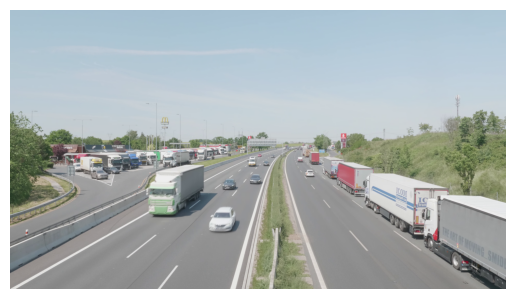

In [12]:
from matplotlib import pyplot as plt

plt.axis("off")
plt.imshow(frame_rgb)

In [15]:
predictions = detect_vehicles(frame, model)
print(predictions[0])
print(f"Number of predictions in frame {len(predictions)}")

{'box': [3188.5341796875, 1426.808349609375, 3837.841552734375, 2146.60498046875], 'conf_score': 0.940484881401062, 'cls_id': 7.0}
Number of predictions in frame 19


In [13]:
predictions

[{'box': [3188.5341796875,
   1426.808349609375,
   3837.841552734375,
   2146.60498046875],
  'conf_score': 0.940484881401062,
  'cls_id': 7.0},
 {'box': [2738.4208984375,
   1256.556396484375,
   3401.51513671875,
   1769.9366455078125],
  'conf_score': 0.9319807887077332,
  'cls_id': 7.0},
 {'box': [1536.4735107421875,
   1519.9954833984375,
   1751.5506591796875,
   1716.6090087890625],
  'conf_score': 0.8722544312477112,
  'cls_id': 2.0},
 {'box': [2284.431640625,
   1233.0279541015625,
   2363.2001953125,
   1296.8255615234375],
  'conf_score': 0.8458136320114136,
  'cls_id': 2.0},
 {'box': [1065.972412109375,
   1189.8768310546875,
   1503.8775634765625,
   1597.2645263671875],
  'conf_score': 0.8411266207695007,
  'cls_id': 7.0},
 {'box': [2529.182373046875,
   1174.2161865234375,
   2820.05419921875,
   1440.5123291015625],
  'conf_score': 0.8265657424926758,
  'cls_id': 7.0},
 {'box': [1643.344482421875,
   1306.1090087890625,
   1758.4658203125,
   1392.5164794921875],
  'co

### Capture the Exact Edge Coordinates of a Clip's Reliable Detection Zone

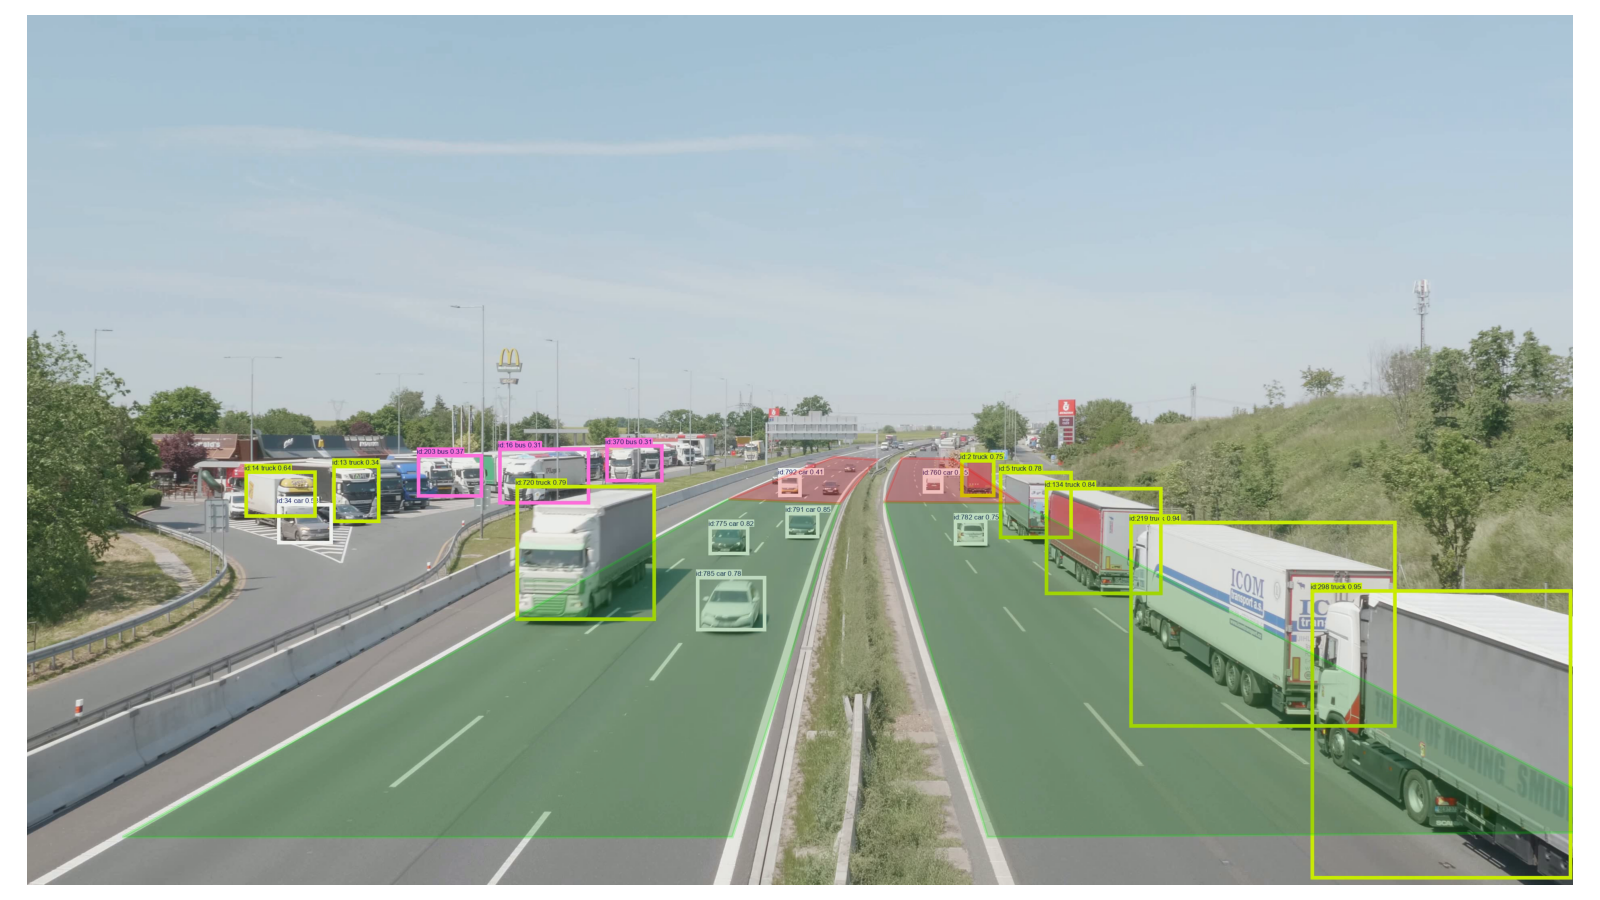

In [35]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from matplotlib.patches import Polygon
from PIL import Image
import numpy as np

img = Image.open("assets/rdz-fz-nohighlight.png")  

fig, ax = plt.subplots(1, figsize=(16, 9))
ax.imshow(img)

left_rdz_zpoints = [(238, 2041),  # bottom-left corner
                    (1743, 1202),  # top-left corner
                    (2019, 1213),  # top-right corner
                    (1752, 2041)] # bottom-right corner

left_farzone_zp = [(1743, 1202),  # bottom-left corner
                   (2005, 1097),  # top-left corner
                   (2112, 1104),  # top-right corner
                   (2019, 1213)]  # bottom-right corner

right_rdz_zpoints = [(2386, 2041),  # bottom-left corner
                    (2130, 1209),  # top-left corner
                    (2467, 1212),  # top-right corner
                    (4050, 2028)] # bottom-right corner

right_farzone_zp = [(2130, 1209),  # bottom-left corner
                   (2172, 1100),  # top-left corner
                   (2300, 1102),  # top-right corner
                   (2467, 1212)]  # bottom-right corner

left_rdz = Polygon(left_rdz_zpoints, closed=True, 
                   facecolor='green', alpha=0.2, 
                   edgecolor='lime', linewidth=2)

left_fz = Polygon(left_farzone_zp, closed=True, 
                   facecolor='red', alpha=0.2, 
                   edgecolor='red', linewidth=2)

right_rdz = Polygon(right_rdz_zpoints, closed=True, 
                   facecolor='green', alpha=0.2, 
                   edgecolor='lime', linewidth=2)

right_fz = Polygon(right_farzone_zp, closed=True, 
                   facecolor='red', alpha=0.2, 
                   edgecolor='red', linewidth=2)

ax.add_patch(left_rdz), ax.add_patch(left_fz)
ax.add_patch(right_rdz), ax.add_patch(right_fz)

w, h = img.size
ax.set_xlim(0, w)
ax.set_ylim(h, 0) 
ax.axis('off')
plt.tight_layout()
# plt.savefig("assets/rdz-fz-highlighted.png", dpi=150, bbox_inches='tight')
plt.show()